# 02 · ¿Quién cuenta a los peregrinos?

No existe una serie oficial de asistencia a las Fiestas de San Francisco Javier. Lo que existe son cifras sueltas que funcionarios dan a la prensa. Este notebook toma el registro manual (`datos/manual/registro_cifras_prensa.csv`) y responde tres preguntas:

1. ¿Para qué años hay alguna cifra atribuible?
2. ¿Qué miden esas cifras y quién las da?
3. ¿Qué tanto se contradicen entre sí?

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import plotly.graph_objects as go

from src import config, tema
from src import procesamiento as proc

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

In [2]:
prensa = proc.leer_registro_prensa()
personas = prensa[(prensa["unidad"] == "personas")].copy()
personas[["id", "anio_evento", "medio", "cifra_min", "cifra_max", "que_mide", "momento", "nivel_fuente", "verificacion"]]

,id,anio_evento,medio,cifra_min,cifra_max,que_mide,momento,nivel_fuente,verificacion
0,P01,2020,El Imparcial,140000.0,140000.0,visitantes_totales,referencia_historica,prensa_sin_atribucion,primaria
1,P02,2022,El Diario de Sonora,8000.0,8000.0,caminantes,conteo_parcial,estatal,primaria
2,P03,2023,El Imparcial,60000.0,60000.0,visitantes_totales,balance,municipal_magdalena,primaria
5,P06,2024,El Imparcial,45000.0,45000.0,visitantes_totales,conteo_parcial,municipal_magdalena,primaria
6,P07,2024,El Imparcial,150000.0,150000.0,visitantes_totales,proyeccion,municipal_magdalena,primaria
7,P08,2024,Audiorama Comunicaciones,120000.0,120000.0,visitantes_totales,proyeccion,municipal_magdalena,solo_titular
8,P09,2025,Expreso,12000.0,12000.0,visitantes_totales,referencia_historica,municipal_nogales,primaria
9,P10,2025,Meganoticias,25000.0,25000.0,caminantes,estimacion_en_curso,mixto,primaria
10,P11,2025,Meganoticias,150000.0,150000.0,caminantes,proyeccion,estatal,primaria
11,P12,2025,Uniradio Informa,NaN,NaN,atendidos_proteccion_civil,balance,estatal,primaria


## 1. Cobertura: ¿qué años tienen dato?

Revisamos la prensa de Sonora desde 2010. Una cifra cuenta como **atribuible** si tiene fecha de publicación y una institución o persona detrás (se excluye la cifra de 200-300 mil que circula en guías turísticas sin fuente).

In [3]:
atribuibles = personas[personas["verificacion"] != "no_verificada"].dropna(subset=["anio_evento"])
cobertura = (
    pd.DataFrame({"anio": range(2010, 2027)})
    .merge(
        atribuibles.groupby("anio_evento").agg(
            cifras=("id", "count"),
            con_declarante=("declarante", lambda s: s.notna().sum()),
            instituciones=("nivel_fuente", lambda s: ", ".join(sorted(set(s)))),
        ),
        left_on="anio", right_index=True, how="left",
    )
    .fillna({"cifras": 0, "con_declarante": 0, "instituciones": "—"})
)
cobertura["cifras"] = cobertura["cifras"].astype(int)
cobertura["con_declarante"] = cobertura["con_declarante"].astype(int)
cobertura

,anio,cifras,con_declarante,instituciones
0,2010,0,0,—
1,2011,0,0,—
2,2012,0,0,—
3,2013,0,0,—
4,2014,0,0,—
5,2015,0,0,—
6,2016,0,0,—
7,2017,0,0,—
8,2018,0,0,—
9,2019,0,0,—


In [4]:
sin_dato = cobertura.loc[cobertura["cifras"] == 0, "anio"].tolist()
print(f"Años sin ninguna cifra atribuible: {len(sin_dato)} de {len(cobertura)} -> {sin_dato}")

Años sin ninguna cifra atribuible: 11 de 17 -> [2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2021]


Ninguno de los diez años previos a la pandemia (2010-2019) tiene una sola cifra con nombre y fecha. El único dato de esa época es una referencia retrospectiva ("congrega año con año alrededor de 140 mil personas") que aparece en la nota que anuncia la **suspensión** de 2020, sin atribuirla a nadie.

**2021 se excluye por atípico.** Fue año de pandemia, no hay fuente primaria y las versiones se contradicen: publicaciones en redes sociales hablan de una fiesta presencial con protocolos sanitarios, y una nota de El Sol de Hermosillo (2022) dice que se canceló dos años seguidos. Ninguna versión trae cifra.

## 2. ¿Qué se mide y en qué momento?

In [5]:
pd.crosstab(atribuibles["que_mide"], atribuibles["momento"], margins=True, margins_name="total")

momento,balance,conteo_parcial,estimacion_en_curso,proyeccion,referencia_historica,total
que_mide,,,,,,
atendidos_proteccion_civil,1,0,0,0,0,1
caminantes,0,1,2,2,0,5
visitantes_totales,1,1,0,3,2,7
total,2,2,2,5,2,13


In [6]:
pd.crosstab(atribuibles["nivel_fuente"], atribuibles["momento"], margins=True, margins_name="total")

momento,balance,conteo_parcial,estimacion_en_curso,proyeccion,referencia_historica,total
nivel_fuente,,,,,,
estatal,1,1,0,1,0,3
mixto,0,0,1,0,0,1
municipal_magdalena,1,1,0,2,0,4
municipal_nogales,0,0,0,2,1,3
prensa_sin_atribucion,0,0,1,0,1,2
total,2,2,2,5,2,13


- Solo **una** cifra de visitantes totales es un balance posterior al evento (2023). El resto son proyecciones, conteos parciales o referencias a "años anteriores".
- Las cifras salen de al menos cuatro lugares distintos: Ayuntamiento de Magdalena, Ayuntamiento de Nogales, Protección Civil estatal y prensa sin atribución.
- En 2025, Protección Civil estatal cerró el operativo **sin cifra** (registro P12).

## 3. ¿Qué tanto se contradicen?

Comparamos, dentro de cada año, la cifra más baja contra la más alta. Mezclan cosas distintas (caminantes vs visitantes), y justo ese es el punto: un lector que busca "cuánta gente va" encuentra todas en la misma semana.

In [7]:
dispersion = (
    atribuibles.dropna(subset=["cifra_min"])
    .groupby("anio_evento")
    .agg(minimo=("cifra_min", "min"), maximo=("cifra_max", "max"), cifras=("id", "count"))
)
dispersion["veces"] = (dispersion["maximo"] / dispersion["minimo"]).round(1)
dispersion

,minimo,maximo,cifras,veces
anio_evento,,,,
2020,140000.0,140000.0,1,1.0
2022,8000.0,8000.0,1,1.0
2023,60000.0,60000.0,1,1.0
2024,45000.0,150000.0,3,3.3
2025,12000.0,150000.0,3,12.5
2026,25000.0,120000.0,3,4.8


In [8]:
anio_2025 = atribuibles[(atribuibles["anio_evento"] == 2025) & atribuibles["cifra_min"].notna()]
anio_2025[["fecha_publicacion", "medio", "cifra_min", "cifra_max", "que_mide", "declarante", "nota"]]

,fecha_publicacion,medio,cifra_min,cifra_max,que_mide,declarante,nota
8,2025-09-25,Expreso,12000.0,12000.0,visitantes_totales,Juan Francisco Gim,"""En años anteriores se han llegado a recibir h..."
9,2025-09-30,Meganoticias,25000.0,25000.0,caminantes,NaN,"""Supera este año las 25 mil personas"" (Nogales..."
10,2025-09-30,Meganoticias,150000.0,150000.0,caminantes,NaN,"""Se espera la participación de más de 150 mil ..."


En **una sola semana de 2025** (25 al 30 de septiembre) se publicaron "hasta doce mil visitantes" (alcalde de Nogales), "más de 25 mil" caminantes desde Nogales y "más de 150 mil caminantes" a nivel estatal. Entre la más baja y la más alta hay 12.5 veces de diferencia.

## 4. Figura: quién dice qué, cuándo

Interactiva: outputs/figuras/02_quien_dice_que.html


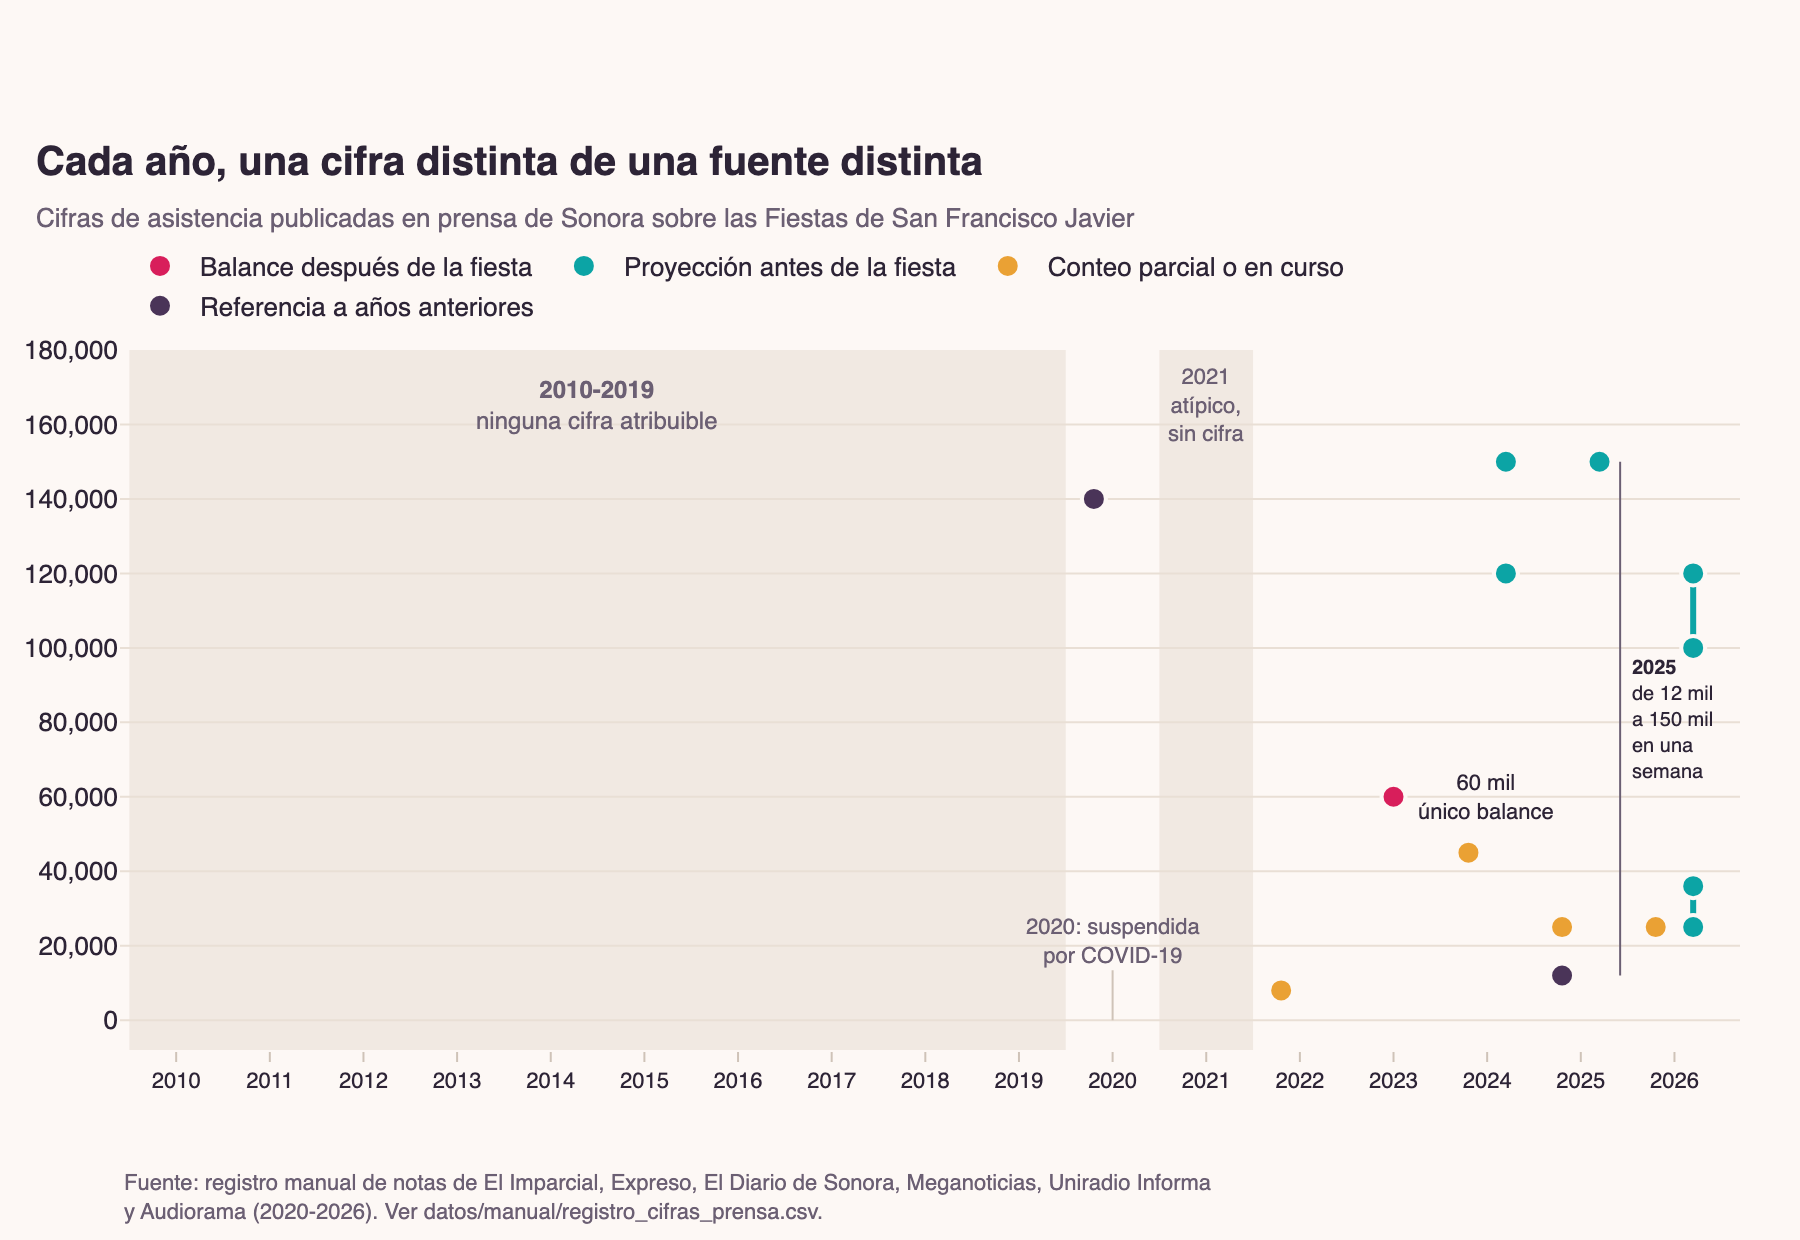

In [9]:
COLOR_MOMENTO = {
    "balance": (tema.PROTAGONISTA, "Balance después de la fiesta"),
    "proyeccion": (tema.SECUNDARIO, "Proyección antes de la fiesta"),
    "conteo_parcial": (tema.TERCIARIO, "Conteo parcial o en curso"),
    "estimacion_en_curso": (tema.TERCIARIO, "Conteo parcial o en curso"),
    "referencia_historica": (tema.CONTORNO, "Referencia a años anteriores"),
}
DESPLAZAMIENTO = {"balance": 0, "proyeccion": 0.2, "conteo_parcial": -0.2, "estimacion_en_curso": -0.2, "referencia_historica": -0.2}

graf = atribuibles.dropna(subset=["cifra_min"]).copy()
graf["x"] = graf["anio_evento"].astype(float) + graf["momento"].map(DESPLAZAMIENTO)
graf["hover"] = (
    "<b>" + graf["medio"] + "</b> · " + graf["fecha_publicacion"].dt.strftime("%d/%m/%Y").fillna("s/f")
    + "<br>" + graf["que_mide"].str.replace("_", " ") + "<br>"
    + graf["declarante"].fillna("Sin declarante") + "<br>" + graf["cargo"].fillna("")
)

fig = go.Figure()
fig.add_vrect(x0=2009.5, x1=2019.5, fillcolor=tema.CUADRICULA, opacity=0.6, line_width=0, layer="below")
fig.add_vrect(x0=2020.5, x1=2021.5, fillcolor=tema.CUADRICULA, opacity=0.6, line_width=0, layer="below")
fig.add_annotation(x=2014.5, y=165000, text="<b>2010-2019</b><br>ninguna cifra atribuible", showarrow=False,
                   font=dict(color=tema.TEXTO_SUAVE, size=12))
fig.add_annotation(x=2021, y=165000, text="2021<br>atípico,<br>sin cifra", showarrow=False, font=dict(color=tema.TEXTO_SUAVE, size=11))
fig.add_annotation(x=2020, y=0, text="2020: suspendida<br>por COVID-19", showarrow=True, arrowhead=0, ax=0, ay=-40,
                   arrowcolor=tema.NEUTRO, font=dict(color=tema.TEXTO_SUAVE, size=11))

vistos = set()
for momento, (color, etiqueta) in COLOR_MOMENTO.items():
    sub = graf[graf["momento"] == momento]
    if sub.empty:
        continue
    for _, fila in sub[sub["cifra_max"] > sub["cifra_min"]].iterrows():
        fig.add_trace(go.Scatter(x=[fila["x"]] * 2, y=[fila["cifra_min"], fila["cifra_max"]], mode="lines",
                                 line=dict(color=color, width=3), hoverinfo="skip", showlegend=False))
    fig.add_trace(go.Scatter(
        x=pd.concat([sub["x"], sub.loc[sub["cifra_max"] > sub["cifra_min"], "x"]]),
        y=pd.concat([sub["cifra_min"], sub.loc[sub["cifra_max"] > sub["cifra_min"], "cifra_max"]]),
        customdata=pd.concat([sub["hover"], sub.loc[sub["cifra_max"] > sub["cifra_min"], "hover"]]),
        mode="markers", name=etiqueta, showlegend=etiqueta not in vistos,
        marker=dict(color=color, size=12, line=dict(color=tema.FONDO, width=2)),
        hovertemplate="%{y:,} personas<br>%{customdata}<extra></extra>",
    ))
    vistos.add(etiqueta)

fig.add_annotation(x=2023, y=60000, text="60 mil<br>único balance", xanchor="left", xshift=10, showarrow=False,
                   font=dict(color=tema.TEXTO, size=11))
fig.add_shape(type="line", x0=2025.42, x1=2025.42, y0=12000, y1=150000, line=dict(color=tema.TEXTO_SUAVE, width=1))
fig.add_annotation(x=2025.42, y=81000, text="<b>2025</b><br>de 12 mil<br>a 150 mil<br>en una<br>semana", xanchor="left",
                   xshift=4, showarrow=False, align="left", font=dict(color=tema.TEXTO, size=10))
fig.update_layout(
    title=tema.titulo("Cada año, una cifra distinta de una fuente distinta",
                      "Cifras de asistencia publicadas en prensa de Sonora sobre las Fiestas de San Francisco Javier"),
    xaxis=dict(range=[2009.4, 2026.7], dtick=1, tickangle=0, tickfont=dict(size=11)),
    yaxis=dict(range=[-8000, 180000], tickformat=",", title=None),
    height=620, margin=dict(t=175),
)
tema.nota_fuente(fig, "Fuente: registro manual de notas de El Imparcial, Expreso, El Diario de Sonora, Meganoticias, Uniradio Informa<br>y Audiorama (2020-2026). Ver datos/manual/registro_cifras_prensa.csv.")
tema.mostrar(fig, "02_quien_dice_que")

**Lectura:** la gráfica no muestra una tendencia; muestra un hueco y una nube. No hay forma honesta de unir estos puntos con una línea, porque cada uno mide una cosa distinta y casi ninguno es un conteo.

## Conclusiones

- **Ninguno de los 10 años** entre 2010 y 2019 tiene una cifra atribuible; 2021 se excluye por atípico (pandemia, versiones contradictorias, sin cifra).
- Solo existe **un balance posterior** de visitantes totales: 60,000 personas en 2023.
- En la misma semana de 2025 circularon cifras que van de 12 mil a 150 mil.
- La institución que atiende a los caminantes en carretera (Protección Civil) cerró 2025 sin cifra.

In [10]:
cobertura.to_csv(config.DIR_PROCESSED / "cobertura_cifras_por_anio.csv", index=False)
dispersion.to_csv(config.DIR_PROCESSED / "dispersion_cifras_por_anio.csv")